# AI Building Energy Advisor — Assignment 1

Group 14 | MTH4800 | SDG 7 & SDG 13

**Goal:** Explore building energy efficiency data and compare baseline models for heating and cooling load prediction. Data are simulated building configurations, not actual electricity bills.

## 1. Dataset loading
Upload `energy_efficiency_data.csv` using the sidebar Files panel or the upload prompt below. The data source is the Kaggle Energy Efficiency dataset, originally the UCI Energy Efficiency dataset.

In [2]:
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()
filename = next((f for f in uploaded if f.lower().endswith(".csv")), None)
if filename is None:
    raise ValueError("Upload energy_efficiency_data.csv")
df = pd.read_csv(io.BytesIO(uploaded[filename]))
print("Shape:", df.shape)
display(df.head())

Saving energy_efficiency_data.csv to energy_efficiency_data (1).csv
Shape: (768, 10)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 2. Data quality & descriptive statistics

In [3]:
print("Column types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
display(df.describe().T)
assert {"Heating_Load", "Cooling_Load"}.issubset(df.columns)

Column types:
Relative_Compactness         float64
Surface_Area                 float64
Wall_Area                    float64
Roof_Area                    float64
Overall_Height               float64
Orientation                    int64
Glazing_Area                 float64
Glazing_Area_Distribution      int64
Heating_Load                 float64
Cooling_Load                 float64
dtype: object

Missing values:
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Relative_Compactness,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
Surface_Area,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
Wall_Area,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
Roof_Area,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
Overall_Height,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
Orientation,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
Glazing_Area,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
Glazing_Area_Distribution,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Heating_Load,768.0,22.307201,10.090196,6.01,12.9925,18.95,31.6675,43.10
Cooling_Load,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


## 3. Exploratory Data Analysis
Plot the target distributions, feature correlations and how building features relate to heating load. Interpret actual plots before writing the report.

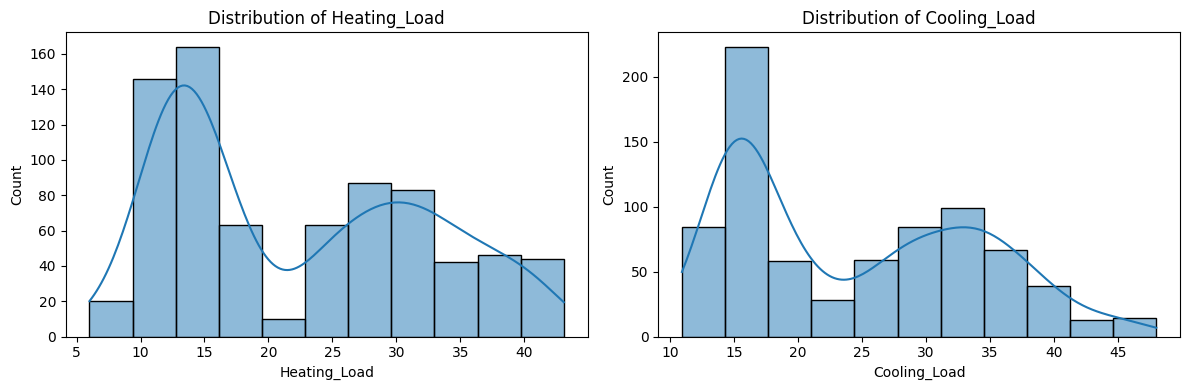

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axs, ["Heating_Load", "Cooling_Load"]):
    sns.histplot(df[target], kde=True, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

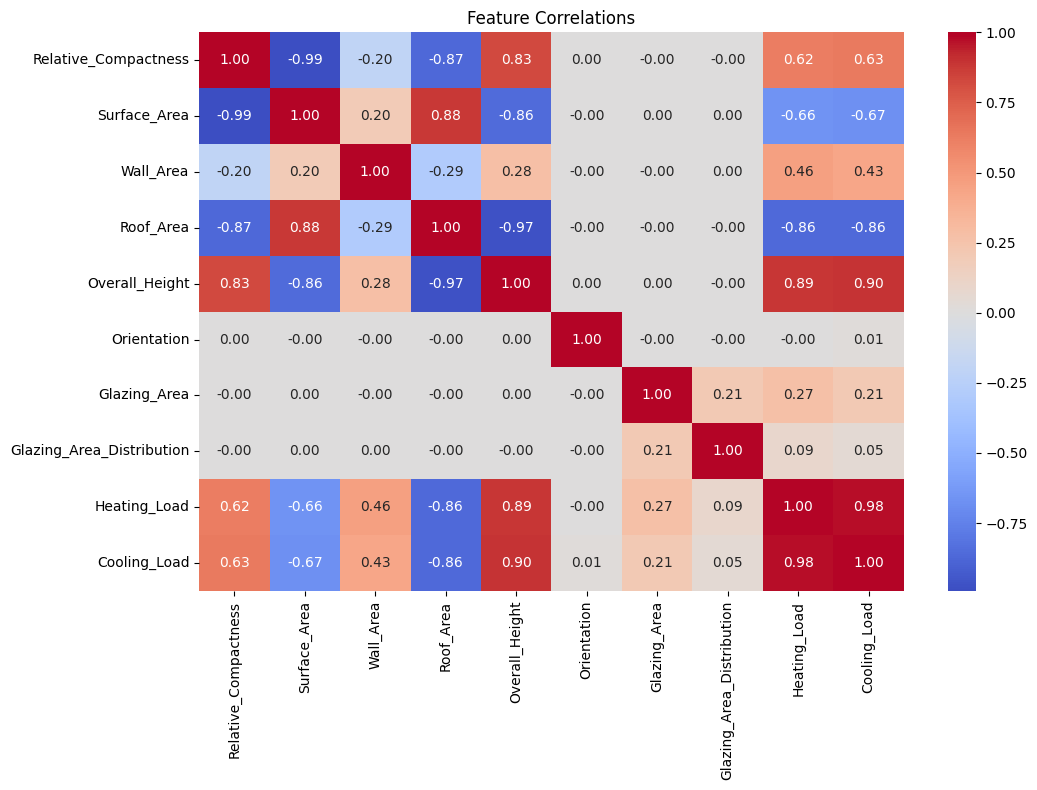

In [5]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlations")
plt.tight_layout()
plt.show()

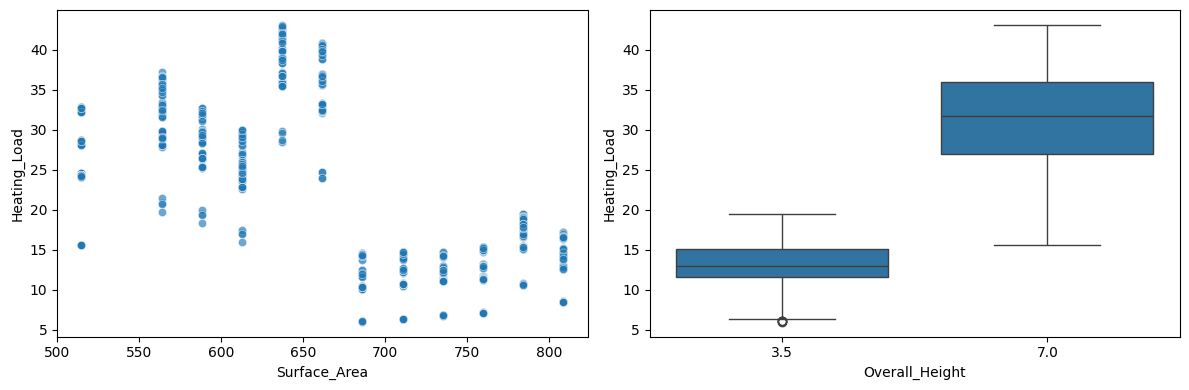

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="Surface_Area", y="Heating_Load", ax=axes[0], alpha=.65)
sns.boxplot(data=df, x="Overall_Height", y="Heating_Load", ax=axes[1])
plt.tight_layout()
plt.show()

## 4. Initial model experiments
Compare Linear Regression to Random Forest using the **same** held-out 20% test set (random_state=42). Each model predicts both energy-load targets. Do not claim these results generalize to real-world buildings: these data are simulations. Note that highly related building configurations can make a random train/test split optimistic.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

targets = ["Heating_Load", "Cooling_Load"]
X = df.drop(columns=targets)
y = df[targets]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    for j, target in enumerate(targets):
        results.append({
            "Model": name, "Target": target,
            "MAE": mean_absolute_error(y_test.iloc[:, j], pred[:, j]),
            "RMSE": np.sqrt(mean_squared_error(y_test.iloc[:, j], pred[:, j])),
            "R2": r2_score(y_test.iloc[:, j], pred[:, j]),
        })
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Target,MAE,RMSE,R2
0,Linear Regression,Heating_Load,2.1820,3.0254,0.9122
1,Linear Regression,Cooling_Load,2.1953,3.1454,0.8932
2,Random Forest,Heating_Load,0.3477,0.4975,0.9976
3,Random Forest,Cooling_Load,1.1664,1.9062,0.9608


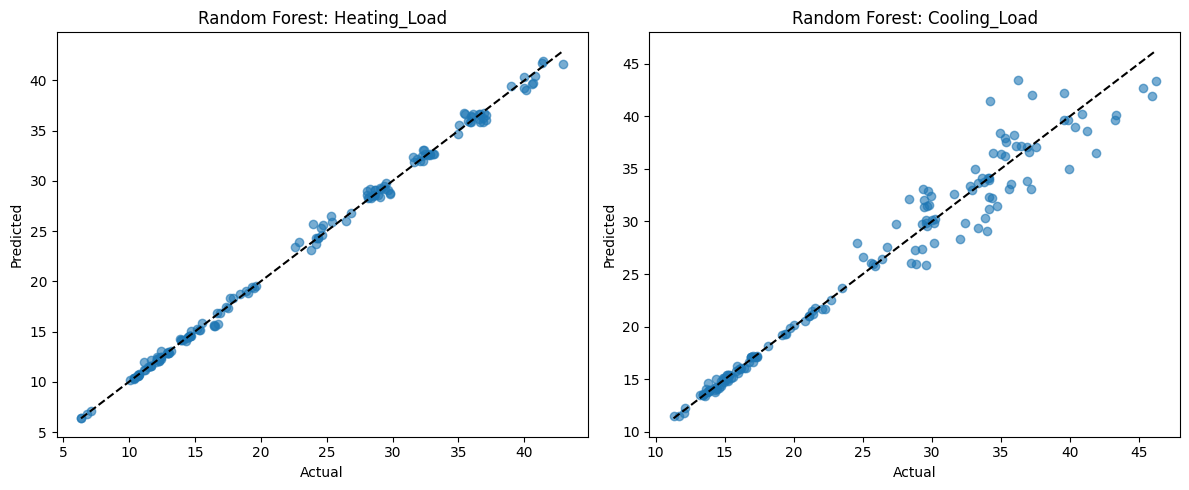

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
rf_pred = predictions["Random Forest"]
for idx, target in enumerate(targets):
    actual = y_test.iloc[:, idx].to_numpy()
    pred = rf_pred[:, idx]
    axes[idx].scatter(actual, pred, alpha=.6)
    bounds = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
    axes[idx].plot(bounds, bounds, "--", color="black")
    axes[idx].set(xlabel="Actual", ylabel="Predicted", title=f"Random Forest: {target}")
plt.tight_layout()
plt.show()

## 5. Interpretation checklist
After running all cells, answer these in English with actual numbers:

1. How many rows, features and missing values are there?
2. What do target distributions show?
3. Which features correlate strongly with the targets? (Correlation does not imply causation.)
4. Which model had lower MAE/RMSE and higher R² for **each** target?
5. What are the limitations of simulated data, small sample size and the evaluation split?
6. How could users compare realistic building designs without extrapolating far beyond training data?

## 6. Suggested concept note headings
Project Name; Overview & Target Users; Problem and SDG Alignment; Dataset & Source; EDA (verified figures and interpretation); Model Choice and First Experiment Results; Input → Model → Output Diagram; Ethical Considerations & Limitations; Plans for Assignments 2 and 3; References.

**Citation:** Tsanas, A. and Xifara, A. (2012), Accurate quantitative estimation of energy performance of residential buildings using statistical machine learning tools, *Energy and Buildings*, 49, 560–567. Dataset: UCI Energy Efficiency (https://archive.ics.uci.edu/dataset/242/energy+efficiency).